# Skin to CAD: fillets of varying radius, blends and rounded threads (C++)

The C++ counterpart of the last part of [`../python/34_skin_to_cad.ipynb`](../python/34_skin_to_cad.ipynb).
Three closed skins carry the features `fit_cad` learned in v16.44.0 (roadmap 6.3.1): a block whose
edge is rounded by a ball shrinking from 0.3 to 0.2 along it, a bar whose freeform top and front
meet at a rolling-ball blend, and a rod whose thread has rounded roots and crests and no cylinder
anywhere. Each is segmented and fitted here through `operations/segment.hpp` and
`operations/fit_primitives.hpp`, which need no CAD kernel.

`fit_cad` builds the solid best through the optional OpenCASCADE backend
(`-DMESHIOPLUSPLUS_WITH_OCCT=ON`), which the single-header amalgamation these notebooks JIT does
not carry. Since v17.9.0 the automatic backend then falls back, with a warning, to the kernel-free
native one: the patches `fit_primitives` explains become analytic STEP faces and the fillet, the
blend and the thread facets, so the counts at the end of each section are the native backend's.
Only an explicit `FitCadBackend::Occt` still throws `Unsupported` naming the flag, and
`fit_cad_has_occt()` says in advance which backend runs. In a build with OpenCASCADE the same call
returns the solid with the feature faces; see [fit CAD](../../doc/fit_cad.md#fillets-blends-and-threads).

In [1]:
#define MESHIOPLUSPLUS_IMPLEMENTATION
#include "../../src/single_include/meshioplusplus/meshioplusplus.hpp"
#include "mio_notebook.hpp"
#include <array>
#include <map>
#include <iostream>
#include <iomanip>
#include <cmath>
using namespace meshioplusplus;
using namespace mio_nb;

// A triangle skin under construction: each quad split in two, each triangle
// wound so its normal points along the direction it is given.
struct NbSkin {
    std::vector<std::array<double, 3>> mPts;
    std::vector<std::array<std::int64_t, 3>> mTris;
    std::int64_t Add(const std::array<double, 3>& rP) {
        mPts.push_back(rP);
        return static_cast<std::int64_t>(mPts.size() - 1);
    }
    void Tri(std::int64_t A, std::int64_t B, std::int64_t C, const std::array<double, 3>& rOut) {
        const auto& p = mPts[A]; const auto& q = mPts[B]; const auto& r = mPts[C];
        const double u[3] = {q[0] - p[0], q[1] - p[1], q[2] - p[2]};
        const double v[3] = {r[0] - p[0], r[1] - p[1], r[2] - p[2]};
        const double n[3] = {u[1] * v[2] - u[2] * v[1], u[2] * v[0] - u[0] * v[2], u[0] * v[1] - u[1] * v[0]};
        if (n[0] * rOut[0] + n[1] * rOut[1] + n[2] * rOut[2] >= 0.0)
            mTris.push_back({A, B, C});
        else
            mTris.push_back({A, C, B});
    }
    Mesh Build() const {
        Mesh m;
        NDArray p(DType::Float64, {mPts.size(), 3});
        for (std::size_t i = 0; i < mPts.size(); ++i)
            for (int k = 0; k < 3; ++k)
                p.As<double>()[i * 3 + k] = mPts[i][k];
        m.AssignPoints(std::move(p));
        NDArray c(DType::Int64, {mTris.size(), 3});
        for (std::size_t i = 0; i < mTris.size(); ++i)
            for (int k = 0; k < 3; ++k)
                c.As<std::int64_t>()[i * 3 + k] = mTris[i][k];
        m.AddCellBlock("triangle", std::move(c));
        return m;
    }
};

using V3 = std::array<double, 3>;
V3 vAdd(const V3& a, const V3& b) { return {a[0] + b[0], a[1] + b[1], a[2] + b[2]}; }
V3 vSub(const V3& a, const V3& b) { return {a[0] - b[0], a[1] - b[1], a[2] - b[2]}; }
V3 vMul(double s, const V3& a) { return {s * a[0], s * a[1], s * a[2]}; }
double vDot(const V3& a, const V3& b) { return a[0] * b[0] + a[1] * b[1] + a[2] * b[2]; }
V3 vCross(const V3& a, const V3& b) { return {a[1] * b[2] - a[2] * b[1], a[2] * b[0] - a[0] * b[2], a[0] * b[1] - a[1] * b[0]}; }
V3 vUnit(const V3& a) { return vMul(1.0 / std::sqrt(vDot(a, a)), a); }
const double kPi = 3.14159265358979323846;

## The three skins

Rows of cross-sections lofted into quads, closed by fans at both ends; each row of a fillet or
blend is an arc of the ball touching both faces, so every point lies on its surface. They are the
`analytic_surfaces` fixtures the C++ and Python tests use.

In [2]:
// Rows of section loops as quads, closed by fans to each end loop's centroid; a
// point without an outward hint faces away from its row's centre.
struct LoopPoint { V3 mP; bool mHasOut; V3 mOut; };

Mesh loft(const std::vector<std::vector<LoopPoint>>& rLoops, const std::vector<V3>& rCentres) {
    NbSkin b;
    std::vector<std::vector<std::int64_t>> id(rLoops.size());
    for (std::size_t i = 0; i < rLoops.size(); ++i)
        for (const LoopPoint& q : rLoops[i])
            id[i].push_back(b.Add(q.mP));
    const std::size_t count = rLoops[0].size();
    for (std::size_t i = 0; i + 1 < rLoops.size(); ++i)
        for (std::size_t j = 0; j < count; ++j) {
            const std::size_t jn = (j + 1) % count;
            const V3 out = rLoops[i][j].mHasOut ? rLoops[i][j].mOut : vSub(rLoops[i][j].mP, rCentres[i]);
            b.Tri(id[i][j], id[i + 1][j], id[i + 1][jn], out);
            b.Tri(id[i][j], id[i + 1][jn], id[i][jn], out);
        }
    for (std::size_t e = 0; e < 2; ++e) {
        const std::size_t i = e == 0 ? 0 : rLoops.size() - 1;
        V3 mid{0, 0, 0};
        for (const LoopPoint& q : rLoops[i]) mid = vAdd(mid, q.mP);
        const std::int64_t c = b.Add(vMul(1.0 / count, mid));
        for (std::size_t j = 0; j < count; ++j)
            b.Tri(c, id[i][j], id[i][(j + 1) % count], {e == 0 ? -1.0 : 1.0, 0.0, 0.0});
    }
    return b.Build();
}

// The block [0, 2] x [0, 1] x [0, 1] whose edge at y = z = 1 is rounded by a ball of
// radius r(x) = 0.25 + 0.05 cos(pi x / 2): each fillet row an exact characteristic circle.
Mesh variableFilletBlock(int N = 48, int K = 16, int M = 6) {
    const double L = 2.0;
    std::vector<std::vector<LoopPoint>> loops;
    std::vector<V3> centres;
    for (int i = 0; i <= N; ++i) {
        const double x = L * i / N, r = 0.25 + 0.05 * std::cos(kPi * x / L);
        const double dr = -0.05 * kPi / L * std::sin(kPi * x / L);
        const V3 c{x, 1 - r, 1 - r}, cd{1.0, -dr, -dr};
        const double len = std::sqrt(vDot(cd, cd)), delta = -r * dr / len;
        const V3 cc = vAdd(c, vMul(delta / len, cd));
        const double rho = std::sqrt(r * r - delta * delta);
        const V3 a = vMul(1.0 / rho, vSub(V3{x, 1.0, 1 - r}, cc));
        const V3 b2 = vSub(V3{x, 1 - r, 1.0}, cc);
        const V3 bv = vUnit(vSub(b2, vMul(vDot(b2, a), a)));
        const double om = std::atan2(vDot(b2, bv), vDot(b2, a));
        std::vector<LoopPoint> loop;
        for (int j = 0; j < M; ++j) loop.push_back({{x, double(j) / M, 0}, true, {0, 0, -1}});
        for (int j = 0; j < M; ++j) loop.push_back({{x, 1, (1 - r) * j / M}, true, {0, 1, 0}});
        for (int j = 0; j < K; ++j)
            loop.push_back({vAdd(cc, vMul(rho, vAdd(vMul(std::cos(om * j / K), a), vMul(std::sin(om * j / K), bv)))), false, {}});
        for (int j = 0; j < M; ++j) loop.push_back({{x, (1 - r) * (1.0 - double(j) / M), 1}, true, {0, 0, 1}});
        for (int j = 0; j < M; ++j) loop.push_back({{x, 0, 1.0 - double(j) / M}, true, {0, -1, 0}});
        loops.push_back(loop);
        centres.push_back(c);
    }
    return loft(loops, centres);
}

// A bar whose top waves with the spine (x, 0, 0.06 cos(4 pi x / 3)) and whose front leans in
// and out by up to 3 degrees, both freeform, the edge between them rounded by a ball of 0.2.
Mesh wavyBar(int N = 96, int K = 8, int M = 8) {
    const double L = 3.0, R = 0.2;
    std::vector<std::vector<LoopPoint>> loops;
    std::vector<V3> centres;
    for (int i = 0; i <= N; ++i) {
        const double x = L * i / N;
        const V3 c{x, 0.0, 0.06 * std::cos(4 * kPi * x / L)};
        const V3 t = vUnit({1.0, 0.0, -0.06 * 4 * kPi / L * std::sin(4 * kPi * x / L)});
        const V3 side{0, 1, 0}, m1 = vCross(t, side);
        const double psi = 3.0 * kPi / 180.0 * std::sin(2 * kPi * x / L);
        const V3 m2 = vAdd(vMul(std::cos(psi), side), vMul(std::sin(psi), m1));
        const V3 q1 = vAdd(c, vMul(R, m1)), q2 = vAdd(c, vMul(R, m2));
        V3 w1 = vCross(m1, t), w2 = vCross(m2, t);
        if (w1[1] > 0) w1 = vMul(-1, w1);
        if (w2[2] > 0) w2 = vMul(-1, w2);
        w1 = vSub(w1, vMul(w1[0] / t[0], t));
        w2 = vSub(w2, vMul(w2[0] / t[0], t));
        const V3 top = vAdd(q1, vMul((q1[1] + 1) / -w1[1], w1));
        const V3 low = vAdd(q2, vMul((q2[2] + 1) / -w2[2], w2));
        const V3 corner{top[0], -1, -1};
        const double om = std::acos(std::max(-1.0, std::min(1.0, vDot(m1, m2))));
        std::vector<LoopPoint> loop;
        for (int j = 0; j < M; ++j) loop.push_back({vAdd(corner, vMul(double(j) / M, vSub(top, corner))), true, {0, -1, 0}});
        for (int j = 0; j < M; ++j) loop.push_back({vAdd(top, vMul(double(j) / M, vSub(q1, top))), true, m1});
        for (int j = 0; j < K; ++j) {
            const double f0 = std::sin((1 - double(j) / K) * om) / std::sin(om), f1 = std::sin(double(j) / K * om) / std::sin(om);
            loop.push_back({vAdd(c, vMul(R, vAdd(vMul(f0, m1), vMul(f1, m2)))), false, {}});
        }
        for (int j = 0; j < M; ++j) loop.push_back({vAdd(q2, vMul(double(j) / M, vSub(low, q2))), true, m2});
        for (int j = 0; j < M; ++j) loop.push_back({vAdd(low, vMul(double(j) / M, vSub(corner, low))), true, {0, 0, -1}});
        loops.push_back(loop);
        centres.push_back(c);
    }
    return loft(loops, centres);
}

// A thread r = f(z - K theta) with straight flanks, its root and crest circular arcs of radius
// 0.2 across the flats (the crest bulging out, the root in), over three turns; the grid follows
// the helices, each end a fan to a point on the axis a pitch inside.
Mesh roundedThreadRod(int Turns = 3, int N = 64) {
    const double P = 0.5, R0 = 0.8, R1 = 1.0, Rr = 0.2, k = P / (2 * kPi);
    const double seg[4] = {0.26 * P, 0.24 * P, 0.26 * P, 0.24 * P};
    const int sub[4] = {4, 3, 4, 3};
    const double half = 0.13 * P, d = std::sqrt(Rr * Rr - half * half);
    std::vector<double> w, rad;
    double at = 0;
    for (int s = 0; s < 4; ++s) {
        for (int i = 0; i < sub[s]; ++i) {
            const double t = double(i) / sub[s], x = seg[s] * t - half;
            w.push_back(at + seg[s] * t);
            rad.push_back(s == 0 ? R0 + d - std::sqrt(Rr * Rr - x * x) : s == 1 ? R0 + (R1 - R0) * t
                          : s == 2 ? R1 - d + std::sqrt(Rr * Rr - x * x) : R1 - (R1 - R0) * t);
        }
        at += seg[s];
    }
    const int per = int(w.size()), rows = per * Turns;
    NbSkin b;
    std::vector<std::vector<std::int64_t>> id(N);
    for (int i = 0; i < N; ++i) {
        const double th = 2 * kPi * i / N;
        for (int j = 0; j <= rows; ++j) {
            const double rj = rad[j % per];
            id[i].push_back(b.Add({rj * std::cos(th), rj * std::sin(th), w[j % per] + P * (j / per) + k * th}));
        }
    }
    auto node = [N, per, rows, &id](int I, int J) -> std::int64_t {
        if (I < N) return id[I][J];
        return J + per <= rows ? id[0][J + per] : -1;
    };
    for (int i = 0; i < N; ++i)
        for (int j = 0; j < rows; ++j) {
            const std::int64_t a = node(i, j), bb = node(i + 1, j), c = node(i + 1, j + 1), dd = node(i, j + 1);
            if (bb < 0 || c < 0) continue;
            const V3 pa = b.mPts[a], pd = b.mPts[dd];
            const double ra = std::hypot(pa[0], pa[1]), rd = std::hypot(pd[0], pd[1]);
            const V3 out{pa[0] / ra, pa[1] / ra, rd > ra + 1e-12 ? -1.0 : rd < ra - 1e-12 ? 1.0 : 0.0};
            b.Tri(a, bb, c, out);
            b.Tri(a, c, dd, out);
        }
    for (int e = 0; e < 2; ++e) {
        std::vector<std::int64_t> loop;
        if (e == 0) {
            for (int i = 0; i < N; ++i) loop.push_back(node(i, 0));
            for (int j = per; j >= 1; --j) loop.push_back(node(0, j));
        } else {
            for (int i = 0; i < N; ++i) loop.push_back(node(i, rows));
            for (int j = rows - 1; j >= rows - per; --j) loop.push_back(node(N - 1, j));
        }
        double lo = 1e300, hi = -1e300;
        for (std::int64_t v : loop) { lo = std::min(lo, b.mPts[v][2]); hi = std::max(hi, b.mPts[v][2]); }
        const std::int64_t c = b.Add({0, 0, e == 0 ? lo - P : hi + P});
        for (std::size_t i = 0; i < loop.size(); ++i) {
            const std::int64_t p = loop[i], q = loop[(i + 1) % loop.size()];
            if (e == 0) b.mTris.push_back({c, q, p});
            else b.mTris.push_back({c, p, q});
        }
    }
    return b.Build();
}

## Segment and fit, then ask for the solid

`segment` splits each skin at its creases and, with a curvature tolerance, where a fillet's or a
blend's curvature departs from its neighbours'; `fit_primitives` then explains what it can as planes,
spheres, cylinders, cones and tori. The fillet of varying radius, the blend, the freeform faces and
the rounded thread are what no primitive explains (`none` below): exactly the patches `fit_cad`'s
fillet, blend and helical fits take over. Each skin is drawn by `segment:patch`.

In [3]:
const char* kTypes[] = {"none", "plane", "sphere", "cylinder", "cone", "torus"};

Mesh fitAndShow(const Mesh& rSkin, double CurvatureTolerance, double Azimuth, double Elevation) {
    SegmentOptions so;
    so.mCurvatureTolerance = CurvatureTolerance;
    const SegmentResult seg = segment(rSkin, so);
    const FitPrimitivesResult fit = fit_primitives(seg.mMesh);
    // Each patch of 20 triangles or more: its fitted type and its size.
    const NDArray& label = fit.mMesh.CellData("segment:patch", 0);
    const NDArray& type = fit.mMesh.CellData("fit:type", 0);
    std::map<std::int64_t, std::pair<std::int64_t, std::int64_t>> patches;  // label -> (type, cells)
    for (std::size_t i = 0; i < label.Size(); ++i) {
        auto& entry = patches[label.As<std::int64_t>()[i]];
        entry.first = type.As<std::int64_t>()[i];
        ++entry.second;
    }
    std::cout << label.Size() << " triangles, " << seg.mNumPatches << " patches:";
    for (const auto& kv : patches)
        if (kv.second.second >= 20 && kv.second.first >= 0)
            std::cout << " " << kTypes[kv.second.first] << " (" << kv.second.second << ")";
    std::cout << "\n";
    // Coloured by patch: the fillet, the blend and each face of the thread are their own.
    RenderOptions o;
    o.mColorBy = "segment:patch";
    o.mCmap = "turbo";
    o.mAzimuth = Azimuth;
    o.mElevation = Elevation;
    o.mShading = RenderShading::Smooth;
    o.mBackground = {255, 255, 255, 255};
    xcpp::display(frame_image(fit.mMesh, o, 480, 320));
    return fit.mMesh;
}

void askForTheSolid(const Mesh& rFitted) {
    // Without OpenCASCADE the automatic backend falls back to the native one.
    const FitCadResult r = fit_cad(rFitted);
    std::cout << (r.mBackend == FitCadBackend::Occt ? "occt" : "native") << ": valid " << r.mValid
              << ", " << r.mNumFaces << " faces: fillet " << r.mNumFillet
              << " (varying " << r.mNumVariableFillet << ", blend " << r.mNumBlend << "), helical "
              << r.mNumHelical << " (rounded " << r.mNumRoundedThread << "), B-spline " << r.mNumBspline
              << ", faceted " << r.mNumFacetedFaces << "\n";
}

### A fillet of varying radius

The fillet runs between two planes, but no one radius explains it: with the backend, `fit_cad`
gives each vertex its own ball and fits the radii as a law along the edge (`num_variable_fillet`).

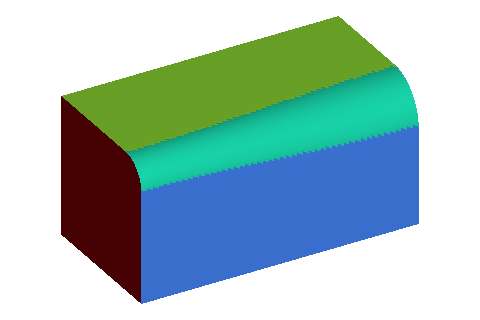

3920 triangles, 7 patches: plane (576) plane (624) none (1440) plane (624) plane (576) plane (40) plane (40)
fit_cad: this build has no OpenCASCADE backend; rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON (OpenCASCADE 7.6 or later)


In [4]:
Mesh blockFit = fitAndShow(variableFilletBlock(), 3.0, 60.0, 30.0);
askForTheSolid(blockFit);

### A blend between two freeform faces

Neither the wavy top nor the leaning front is a primitive, so the fillet between them has no
analytic neighbour: with the backend, the blend is fitted after the two freeform B-spline faces,
against them (`num_blend`).

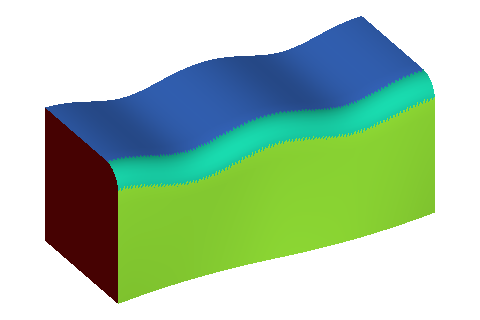

7760 triangles, 7 patches: plane (1536) none (1632) none (1344) none (1632) plane (1536) plane (40) plane (40)
fit_cad: this build has no OpenCASCADE backend; rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON (OpenCASCADE 7.6 or later)


In [5]:
Mesh barFit = fitAndShow(wavyBar(), 3.0, 60.0, 30.0);
askForTheSolid(barFit);

### A rounded thread with no cylinder

The root and crest are arcs, so no cylinder or cone gives the thread's axis: with the backend,
each patch finds the screw it fits itself (`num_rounded_thread` counts the root and crest).

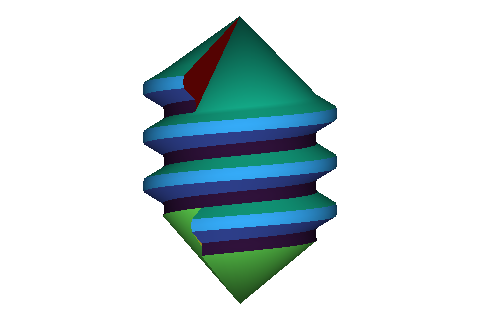

5504 triangles, 10 patches: none (1528) none (1146) none (1528) none (1210) none (64)
fit_cad: this build has no OpenCASCADE backend; rebuild with -DMESHIOPLUSPLUS_WITH_OCCT=ON (OpenCASCADE 7.6 or later)


In [6]:
Mesh rodFit = fitAndShow(roundedThreadRod(), 0.0, 30.0, 0.0);
askForTheSolid(rodFit);

## Refining the patches first

`mRefineSegmentation` (v17.11.0) refines the patches by `refine_patches` before the solid is
built, as `fit_cad(..., refine_segmentation=True)` does in the Python notebook: here, natively,
the fillet block's and the wavy bar's patches come back explained by primitives, so far fewer
faces are facets (`mRefinementKept` says the solid was built from the refined patches; the
native backend always keeps them). Only an explicit `FitCadBackend::Occt` still throws in this
build.

In [ ]:
for (const Mesh* pFitted : {&blockFit, &barFit}) {
    for (bool refine : {false, true}) {
        FitCadOptions o;
        o.mRefineSegmentation = refine;
        const FitCadResult r = fit_cad(*pFitted, {}, o);
        std::cout << (pFitted == &blockFit ? "fillet block" : "wavy bar    ")
                  << (refine ? ", refined: " : ", default: ") << r.mNumFaces << " faces, "
                  << r.mNumFacetedFaces << " faceted, refinement kept " << r.mRefinementKept << "\n";
    }
}
if (!fit_cad_has_occt()) {
    FitCadOptions occt;
    occt.mBackend = FitCadBackend::Occt;
    try {
        fit_cad(barFit, {}, occt);
    } catch (const Unsupported& rErr) {
        std::cout << "FitCadBackend::Occt: " << rErr.what() << "\n";
    }
}